# IPL Player & Team Stats Analysis
### Python for Data Science — Micro Project

**Objective:** Analyze IPL (Indian Premier League) match and ball-by-ball data to explore team performance, top players, toss impact, venue trends, and season-wise patterns using Python (Pandas, Matplotlib, Seaborn).

**Dataset:** IPL Complete Dataset (2008–2024) — Kaggle: search "IPL Complete Dataset" by Patrick B
Files needed: `matches.csv` and `deliveries.csv`


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
%matplotlib inline


## 2. Load the Datasets

In [2]:
matches = pd.read_csv('matches.csv')
deliveries = pd.read_csv('deliveries.csv')

print("Matches shape:", matches.shape)
print("Deliveries shape:", deliveries.shape)
matches.head()


Matches shape: (1095, 20)
Deliveries shape: (260920, 17)


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


## 3. Basic Info & Data Cleaning

In [3]:
matches.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   object 
 2   city             1044 non-null   object 
 3   date             1095 non-null   object 
 4   match_type       1095 non-null   object 
 5   player_of_match  1090 non-null   object 
 6   venue            1095 non-null   object 
 7   team1            1095 non-null   object 
 8   team2            1095 non-null   object 
 9   toss_winner      1095 non-null   object 
 10  toss_decision    1095 non-null   object 
 11  winner           1090 non-null   object 
 12  result           1095 non-null   object 
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   object 
 17  method        

In [4]:
# Check missing values
matches.isnull().sum().sort_values(ascending=False).head(10)


method             1074
city                 51
result_margin        19
player_of_match       5
winner                5
target_runs           3
target_overs          3
id                    0
date                  0
season                0
dtype: int64

In [5]:
# Drop rows with no result (abandoned matches) and fill minor gaps
matches = matches[matches['result'] != 'no result'] if 'result' in matches.columns else matches
matches['city'] = matches['city'].fillna('Unknown')
matches = matches.drop_duplicates()

print("Cleaned shape:", matches.shape)


Cleaned shape: (1090, 20)


## 4. Matches Played Per Season

C:\Users\DELL\AppData\Local\Temp\ipykernel_4472\909317839.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=matches, x=season_col, palette='viridis')


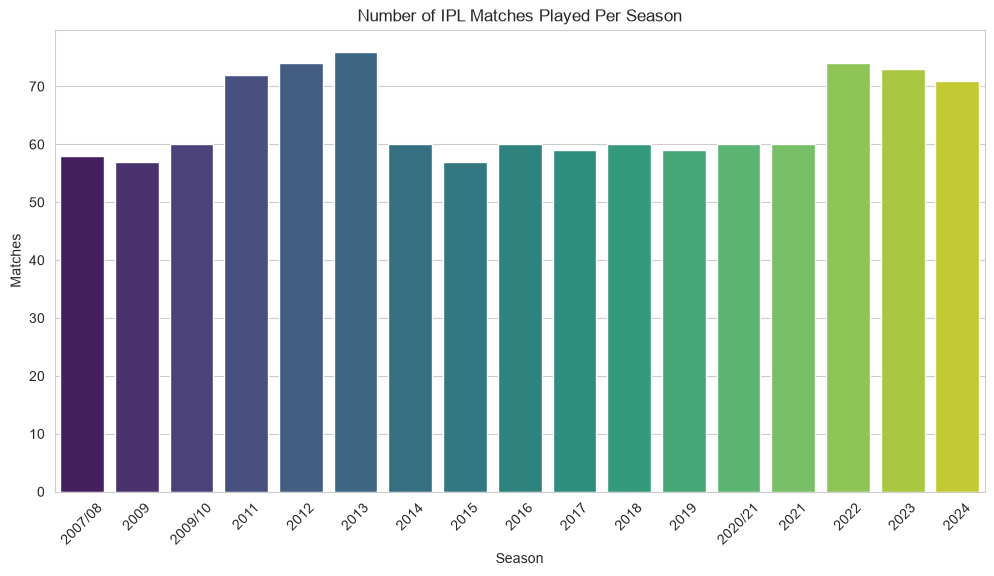

In [6]:
season_col = 'season' if 'season' in matches.columns else 'Season'

plt.figure(figsize=(12,6))
sns.countplot(data=matches, x=season_col, palette='viridis')
plt.title('Number of IPL Matches Played Per Season')
plt.xlabel('Season')
plt.ylabel('Matches')
plt.xticks(rotation=45)
plt.show()


## 5. Most Successful Teams (Total Wins)

C:\Users\DELL\AppData\Local\Temp\ipykernel_4472\3349228296.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_teams.values, y=top_teams.index, palette='mako')


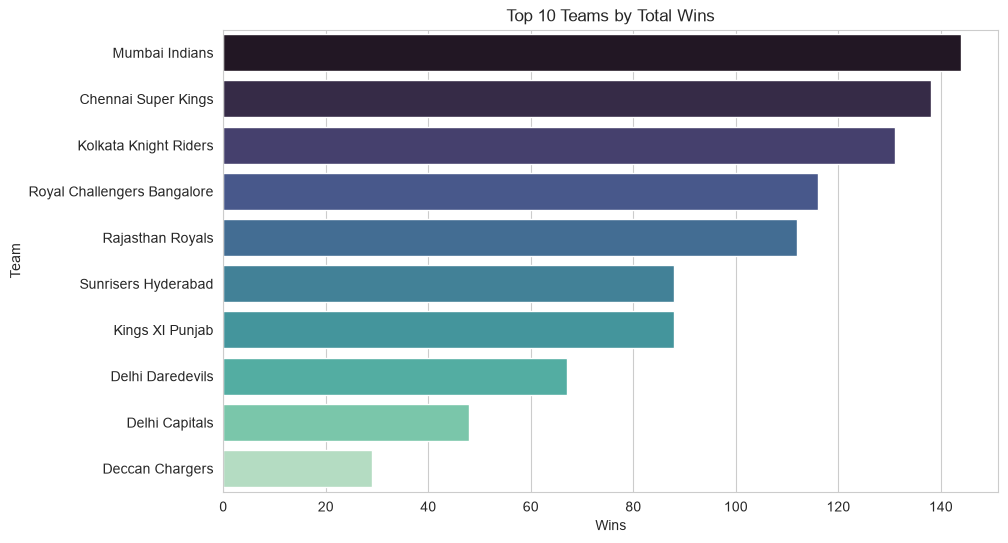

In [7]:
winner_col = 'winner' if 'winner' in matches.columns else 'Winner'
top_teams = matches[winner_col].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top_teams.values, y=top_teams.index, palette='mako')
plt.title('Top 10 Teams by Total Wins')
plt.xlabel('Wins')
plt.ylabel('Team')
plt.show()


## 6. Toss Decision Impact — Does Winning the Toss Help?

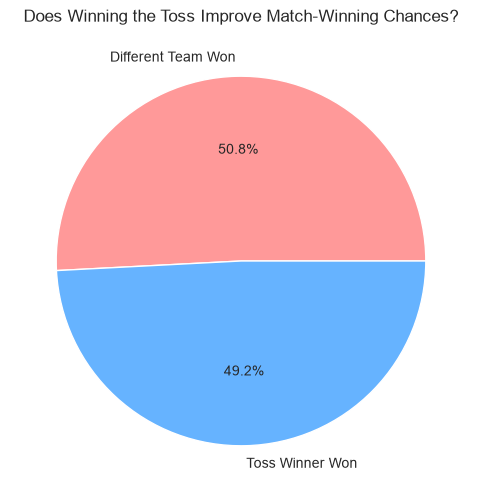

In [8]:
matches['toss_match_winner_same'] = matches['toss_winner'] == matches[winner_col]

plt.figure(figsize=(6,6))
matches['toss_match_winner_same'].value_counts().plot.pie(
    autopct='%1.1f%%', labels=['Different Team Won', 'Toss Winner Won'], colors=['#ff9999','#66b3ff']
)
plt.title('Does Winning the Toss Improve Match-Winning Chances?')
plt.ylabel('')
plt.show()


C:\Users\DELL\AppData\Local\Temp\ipykernel_4472\3814447220.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=matches, x='toss_decision', palette='Set2')


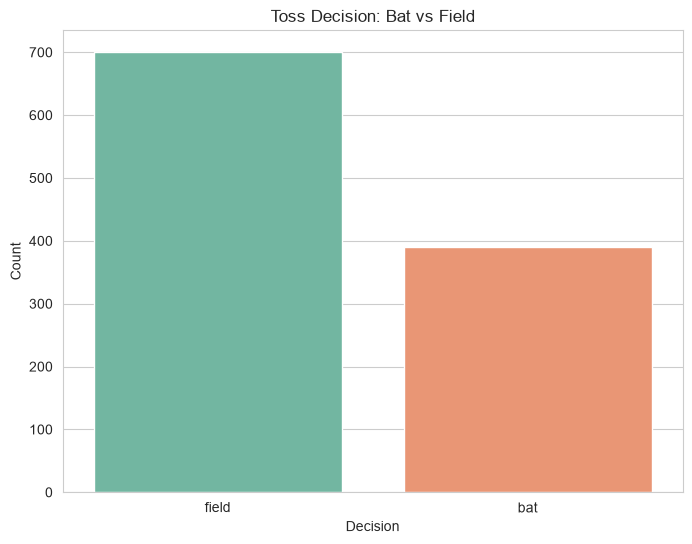

In [9]:
plt.figure(figsize=(8,6))
sns.countplot(data=matches, x='toss_decision', palette='Set2')
plt.title('Toss Decision: Bat vs Field')
plt.xlabel('Decision')
plt.ylabel('Count')
plt.show()


## 7. Top Run Scorers (All-Time)

C:\Users\DELL\AppData\Local\Temp\ipykernel_4472\1803325380.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_scorers.values, y=top_scorers.index, palette='rocket')


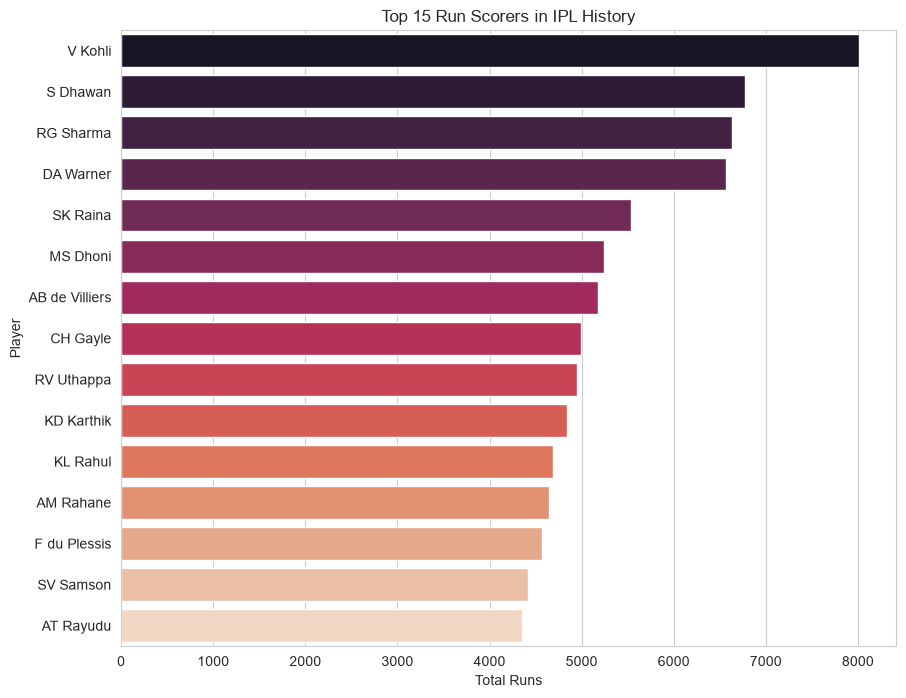

In [10]:
batsman_col = 'batter' if 'batter' in deliveries.columns else 'batsman'
top_scorers = deliveries.groupby(batsman_col)['batsman_runs'].sum().sort_values(ascending=False).head(15)

plt.figure(figsize=(10,8))
sns.barplot(x=top_scorers.values, y=top_scorers.index, palette='rocket')
plt.title('Top 15 Run Scorers in IPL History')
plt.xlabel('Total Runs')
plt.ylabel('Player')
plt.show()


## 8. Top Wicket Takers (All-Time)

C:\Users\DELL\AppData\Local\Temp\ipykernel_4472\2949211989.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_bowlers.values, y=top_bowlers.index, palette='crest')


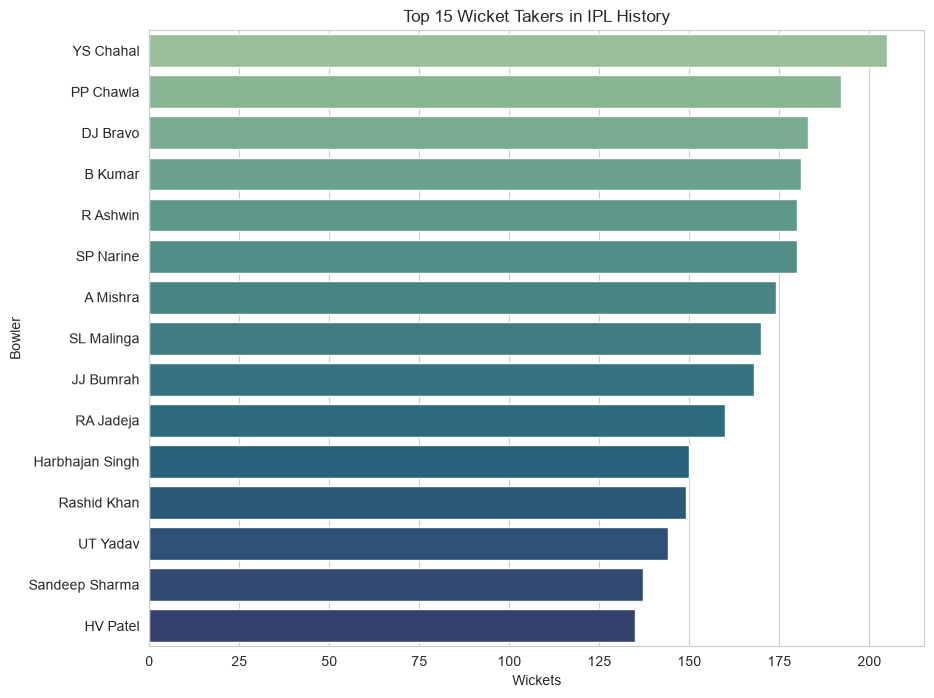

In [11]:
bowler_wickets = deliveries[deliveries['dismissal_kind'].notnull() &
                             (~deliveries['dismissal_kind'].isin(['run out', 'retired hurt', 'obstructing the field']))]
top_bowlers = bowler_wickets.groupby('bowler')['dismissal_kind'].count().sort_values(ascending=False).head(15)

plt.figure(figsize=(10,8))
sns.barplot(x=top_bowlers.values, y=top_bowlers.index, palette='crest')
plt.title('Top 15 Wicket Takers in IPL History')
plt.xlabel('Wickets')
plt.ylabel('Bowler')
plt.show()


## 9. Most Sixes and Fours

C:\Users\DELL\AppData\Local\Temp\ipykernel_4472\2006597001.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sixes.values, y=sixes.index, ax=axes[0], palette='flare')
C:\Users\DELL\AppData\Local\Temp\ipykernel_4472\2006597001.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=fours.values, y=fours.index, ax=axes[1], palette='flare')


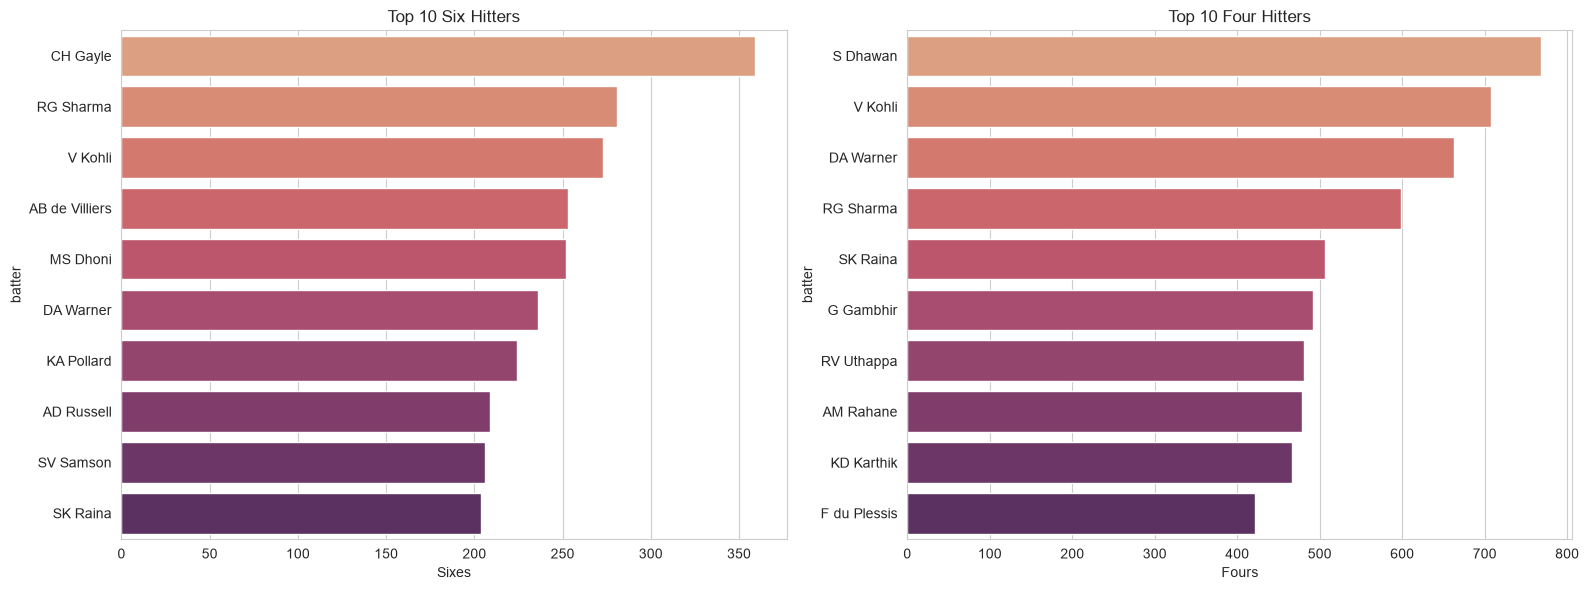

In [12]:
sixes = deliveries[deliveries['batsman_runs'] == 6].groupby(batsman_col).size().sort_values(ascending=False).head(10)
fours = deliveries[deliveries['batsman_runs'] == 4].groupby(batsman_col).size().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16,6))
sns.barplot(x=sixes.values, y=sixes.index, ax=axes[0], palette='flare')
axes[0].set_title('Top 10 Six Hitters')
axes[0].set_xlabel('Sixes')

sns.barplot(x=fours.values, y=fours.index, ax=axes[1], palette='flare')
axes[1].set_title('Top 10 Four Hitters')
axes[1].set_xlabel('Fours')

plt.tight_layout()
plt.show()


## 10. Most Popular Venues

C:\Users\DELL\AppData\Local\Temp\ipykernel_4472\3524631275.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_venues.values, y=top_venues.index, palette='cubehelix')


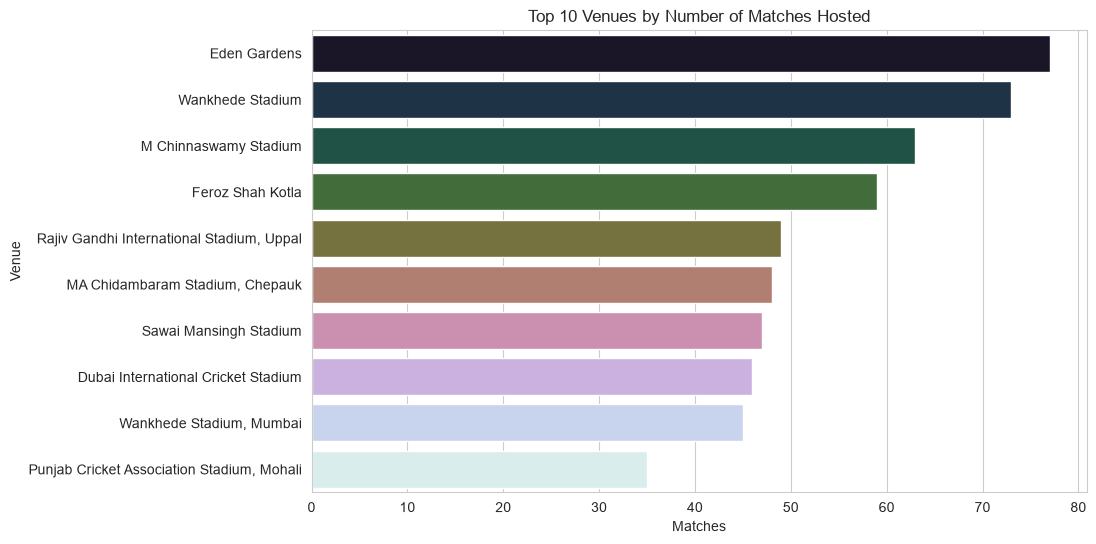

In [13]:
top_venues = matches['venue'].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top_venues.values, y=top_venues.index, palette='cubehelix')
plt.title('Top 10 Venues by Number of Matches Hosted')
plt.xlabel('Matches')
plt.ylabel('Venue')
plt.show()


## 11. Player of the Match — Most Awards

C:\Users\DELL\AppData\Local\Temp\ipykernel_4472\1727835936.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_potm.values, y=top_potm.index, palette='magma')


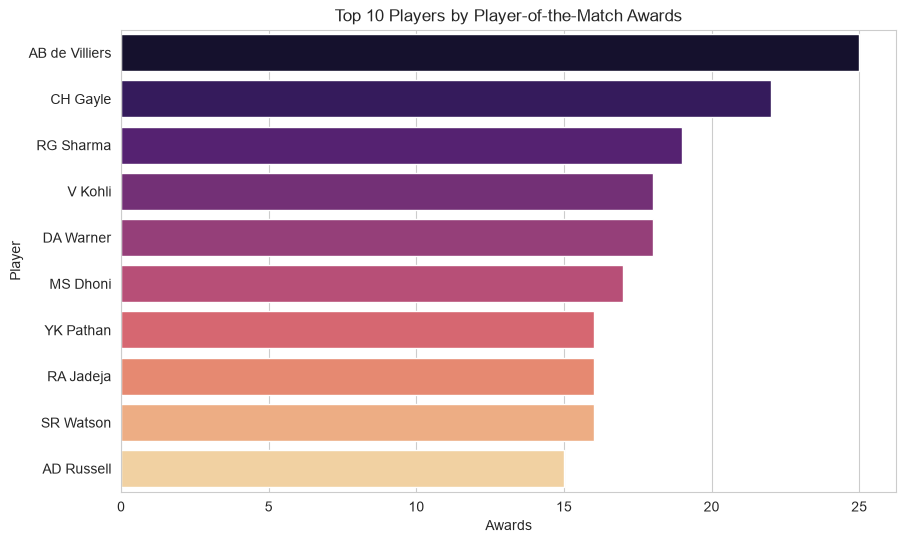

In [14]:
potm_col = 'player_of_match' if 'player_of_match' in matches.columns else 'Player_of_Match'
top_potm = matches[potm_col].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=top_potm.values, y=top_potm.index, palette='magma')
plt.title('Top 10 Players by Player-of-the-Match Awards')
plt.xlabel('Awards')
plt.ylabel('Player')
plt.show()


## 12. Win Margin Analysis (By Runs vs By Wickets)

C:\Users\DELL\AppData\Local\Temp\ipykernel_4472\2724605741.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=matches, x='result', palette='Set3')


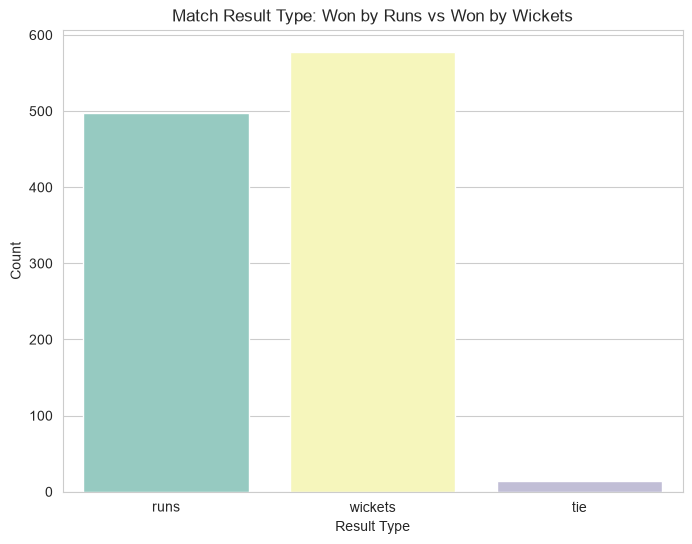

In [15]:
plt.figure(figsize=(8,6))
sns.countplot(data=matches, x='result', palette='Set3')
plt.title('Match Result Type: Won by Runs vs Won by Wickets')
plt.xlabel('Result Type')
plt.ylabel('Count')
plt.show()


## 13. Key Insights & Conclusion

After running the analysis above, summarize your findings here. Some prompts to guide you:

- **Dominant teams:** Which team(s) have historically won the most matches?
- **Toss impact:** Does winning the toss meaningfully improve win chances? Do teams prefer batting or fielding first?
- **Star players:** Who are the standout run-scorers and wicket-takers across IPL history?
- **Venues:** Are certain venues more "high-scoring" or team-favorable (you can extend the analysis to check this)?
- **Trends over seasons:** Has the number of matches or style of play (e.g., more sixes) changed as IPL has grown?

*(Fill this section in with your own observations once you've run the notebook — this interpretation is usually the most valuable part for grading.)*
